# Vietnamese Title Processing and Weak-Label Construction

This notebook generates the statistics and figures for Section 3.4. It reads the audited manifest produced by `fashion_vn.prepare`, so every number reflects the current preprocessing rules in `fashion_vn/text.py`.

The analysis distinguishes three objects: the original seller title, the normalized/tokenized representation used for training, and the weak attributes extracted by the rule-based lexicon. Weak attributes are title-derived signals, not human-verified visual ground truth.

Figures are exported as 300-dpi PNG and SVG files under `outputs/figures/title_processing/`.

In [1]:
from pathlib import Path
import json
import csv
import collections
import unicodedata

import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'outputs' / 'prepared' / 'manifest.jsonl').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
MANIFEST = PROJECT_ROOT / 'outputs' / 'prepared' / 'manifest.jsonl'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures' / 'title_processing'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
records = [json.loads(line) for line in MANIFEST.read_text(encoding='utf-8').splitlines() if line.strip()]
N = len(records)

plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelsize': 10,
    'figure.facecolor': 'white', 'axes.facecolor': 'white'
})
C = {'blue':'#2F61A8', 'green':'#58A14F', 'orange':'#E17C05',
     'red':'#C94C4C', 'gray':'#888888', 'purple':'#8C65B5'}

def save_figure(fig, stem):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'{stem}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURE_DIR / f'{stem}.svg', bbox_inches='tight')
    plt.show()

def annotate_bars(ax, values, denominator=None):
    maximum = max(values) if values else 1
    for patch, value in zip(ax.patches, values):
        label = f'{value:,}'
        if denominator:
            label += f' ({100*value/denominator:.1f}%)'
        ax.text(patch.get_width()+maximum*.012, patch.get_y()+patch.get_height()/2,
                label, va='center', fontsize=9)

print(f'Loaded {N:,} records from {MANIFEST}')
print(f'Figures will be exported to {FIGURE_DIR}')

Loaded 10,798 records from D:\RESEARCH\THESIS 2\fashion_vn\outputs\prepared\manifest.jsonl
Figures will be exported to D:\RESEARCH\THESIS 2\fashion_vn\outputs\figures\title_processing


## 3.4.1 Processing overview

A title is retained even when no lexicon item is recognized. Titles flagged as containing several variants or possible negation are excluded from the completed weak-supervision training run, while other records remain available for inference and auditing.

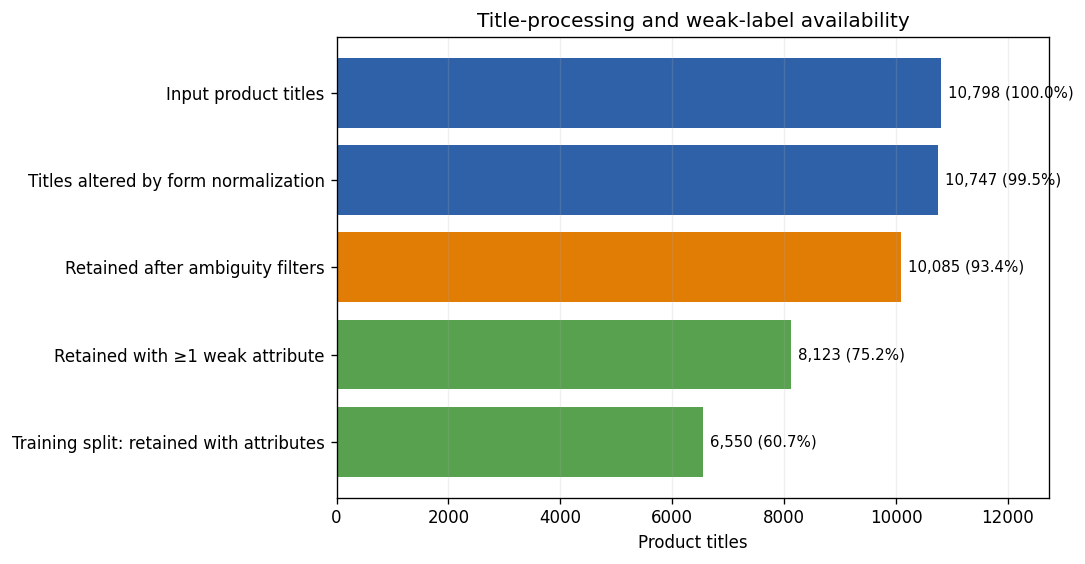

10,747 titles (99.53%) changed under Unicode/case/punctuation/spacing normalization.
713 titles were excluded from the completed weak-supervision run by the multiple-variant or possible-negation filters.
A normalization change is not necessarily a spelling correction; lowercase and punctuation changes also count.


In [2]:
changed = sum(r['title_raw'] != r['title_normalized'] for r in records)
with_attributes = sum(bool(r['title_attributes']) for r in records)
safe = [r for r in records if not any(f in r['flags'] for f in ('listing_multiple_variants', 'possible_negation_review'))]
safe_with_attributes = sum(bool(r['title_attributes']) for r in safe)
train_safe_with_attributes = sum(r['split']=='train' and bool(r['title_attributes']) for r in safe)
overview = collections.OrderedDict([
    ('Input product titles', N),
    ('Titles altered by form normalization', changed),
    ('Retained after ambiguity filters', len(safe)),
    ('Retained with ≥1 weak attribute', safe_with_attributes),
    ('Training split: retained with attributes', train_safe_with_attributes),
])
fig, ax = plt.subplots(figsize=(9, 4.8))
labels, values = list(overview.keys()), list(overview.values())
ax.barh(labels[::-1], values[::-1], color=[C['green'], C['green'], C['orange'], C['blue'], C['blue']])
annotate_bars(ax, values[::-1], denominator=N)
ax.set_xlim(0, N*1.18)
ax.set_xlabel('Product titles')
ax.set_title('Title-processing and weak-label availability')
ax.grid(axis='x', alpha=.2)
save_figure(fig, 'figure_3_4_1_processing_overview')

print(f'{changed:,} titles ({100*changed/N:.2f}%) changed under Unicode/case/punctuation/spacing normalization.')
print(f'{N-len(safe):,} titles were excluded from the completed weak-supervision run by the multiple-variant or possible-negation filters.')
print('A normalization change is not necessarily a spelling correction; lowercase and punctuation changes also count.')

## 3.4.2 Effect of token processing

`Normalized-title tokens` are whitespace-separated strings before lexicon replacement and filtering. `Model tokens` are the final tokens stored in the manifest after multiword attribute phrases are collapsed and selected stopwords, numeric tokens, and one-character tokens are removed.

C:\Users\vthuy\AppData\Local\Temp\ipykernel_19128\26819647.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([normalized_tokens, model_tokens, removed],


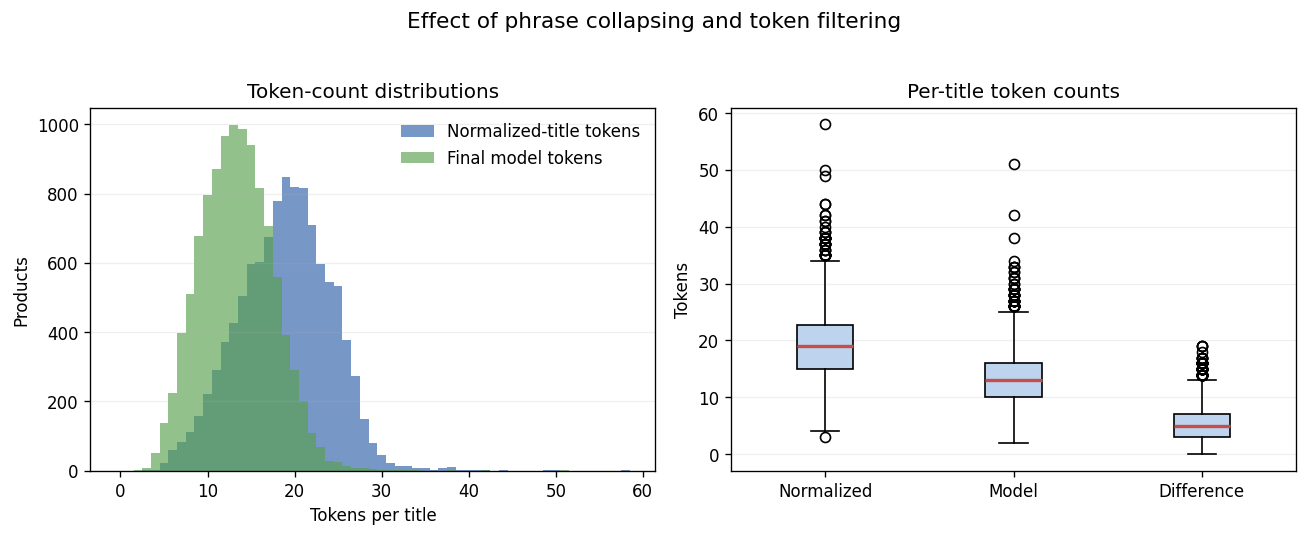

Mean normalized-title tokens: 18.88.
Mean final model tokens: 13.37.
Mean numerical reduction: 5.51 tokens per title.
The difference combines stopword removal with the collapse of multiword expressions; it is not a pure stopword count.


In [3]:
normalized_tokens = np.array([len(r['title_normalized'].split()) for r in records])
model_tokens = np.array([len(r['tokens']) for r in records])
removed = normalized_tokens-model_tokens
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
bins = np.arange(0, max(normalized_tokens.max(), model_tokens.max())+2)-.5
axes[0].hist(normalized_tokens, bins=bins, alpha=.65, color=C['blue'], label='Normalized-title tokens')
axes[0].hist(model_tokens, bins=bins, alpha=.65, color=C['green'], label='Final model tokens')
axes[0].set(xlabel='Tokens per title', ylabel='Products', title='Token-count distributions')
axes[0].legend(frameon=False)
axes[0].grid(axis='y', alpha=.2)
axes[1].boxplot([normalized_tokens, model_tokens, removed],
                tick_labels=['Normalized', 'Model', 'Difference'], patch_artist=True,
                boxprops={'facecolor':'#BED3EE'}, medianprops={'color':C['red'],'linewidth':2})
axes[1].set(title='Per-title token counts', ylabel='Tokens')
axes[1].grid(axis='y', alpha=.2)
fig.suptitle('Effect of phrase collapsing and token filtering', y=1.03, fontsize=13)
save_figure(fig, 'figure_3_4_2_token_processing')

print(f'Mean normalized-title tokens: {normalized_tokens.mean():.2f}.')
print(f'Mean final model tokens: {model_tokens.mean():.2f}.')
print(f'Mean numerical reduction: {removed.mean():.2f} tokens per title.')
print('The difference combines stopword removal with the collapse of multiword expressions; it is not a pure stopword count.')

## 3.4.3 Lexicon mapping and canonicalization

Each match retains its original evidence phrase, canonical value, attribute group, and location. Repeated evidence can occur more than once within one title, whereas `title_attributes` deduplicates canonical values at product level.

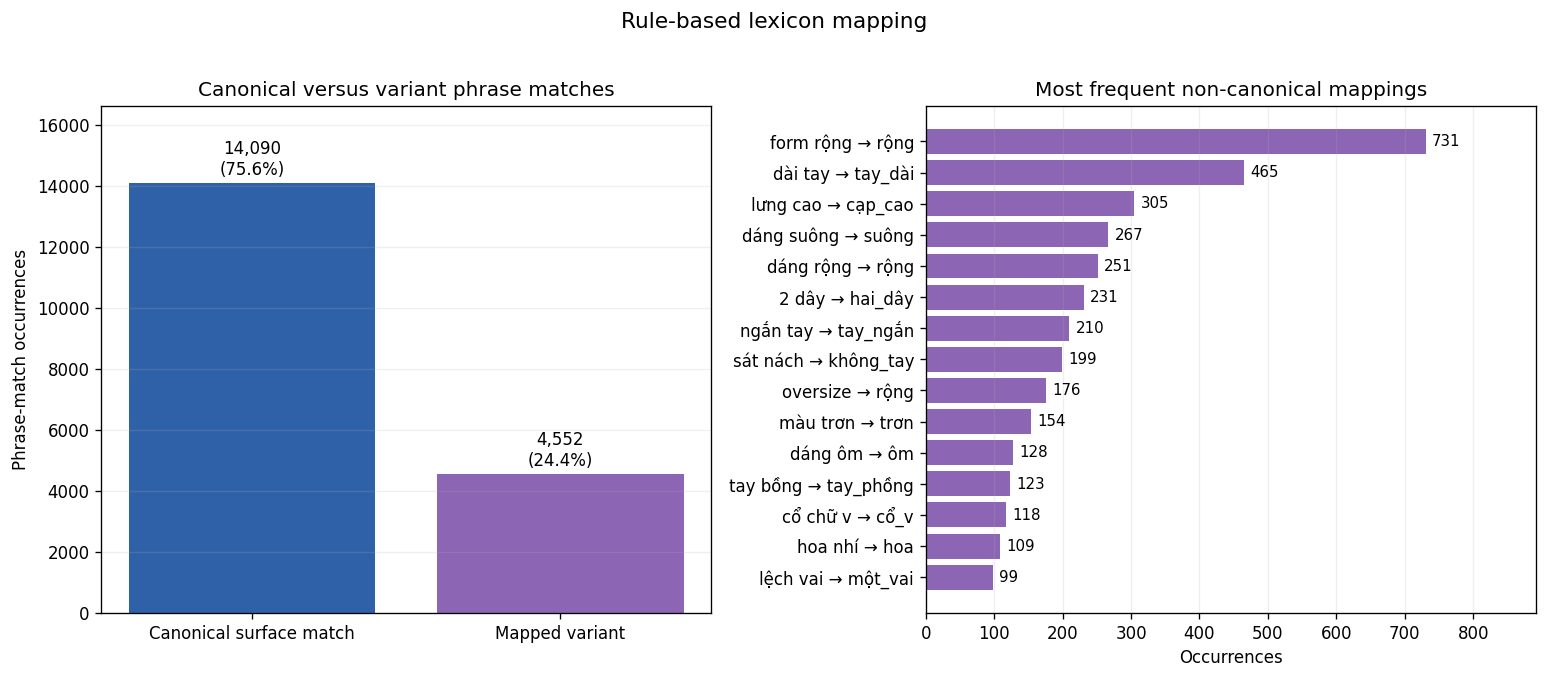

18,642 phrase occurrences produced 17,687 product-level canonical value mentions.
4,552 phrase occurrences (24.42%) used a surface form different from the canonical value.


In [4]:
evidence = [item for r in records for item in r['title_evidence']]
def canonical_surface(value):
    return value.replace('_', ' ')
direct = sum(e['evidence'] == canonical_surface(e['value']) for e in evidence)
variant = len(evidence)-direct
variant_mappings = collections.Counter(
    (e['evidence'], e['value']) for e in evidence
    if e['evidence'] != canonical_surface(e['value'])
)
top_variants = variant_mappings.most_common(15)
mapping_labels = [f'{source} → {target}' for (source, target), _ in top_variants]
mapping_values = [count for _, count in top_variants]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].bar(['Canonical surface match', 'Mapped variant'], [direct, variant],
            color=[C['blue'], C['purple']])
for patch, value in zip(axes[0].patches, [direct, variant]):
    axes[0].text(patch.get_x()+patch.get_width()/2, value+len(evidence)*.015,
                 f'{value:,}\n({100*value/len(evidence):.1f}%)', ha='center')
axes[0].set_ylim(0, max(direct, variant)*1.18)
axes[0].set_ylabel('Phrase-match occurrences')
axes[0].set_title('Canonical versus variant phrase matches')
axes[0].grid(axis='y', alpha=.2)
axes[1].barh(mapping_labels[::-1], mapping_values[::-1], color=C['purple'])
annotate_bars(axes[1], mapping_values[::-1])
axes[1].set_xlim(0, max(mapping_values)*1.22)
axes[1].set_xlabel('Occurrences')
axes[1].set_title('Most frequent non-canonical mappings')
axes[1].grid(axis='x', alpha=.2)
fig.suptitle('Rule-based lexicon mapping', y=1.02, fontsize=13)
save_figure(fig, 'figure_3_4_3_lexicon_mapping')

canonical_mentions = sum(sum(len(v) for v in r['title_attributes'].values()) for r in records)
print(f'{len(evidence):,} phrase occurrences produced {canonical_mentions:,} product-level canonical value mentions.')
print(f'{variant:,} phrase occurrences ({100*variant/len(evidence):.2f}%) used a surface form different from the canonical value.')


## 3.4.4 Weak-label group coverage and value imbalance

Group coverage counts each product once per attribute group. Individual-value frequency also counts each canonical value at most once per product because values are stored as sets during preparation. Groups overlap across products.

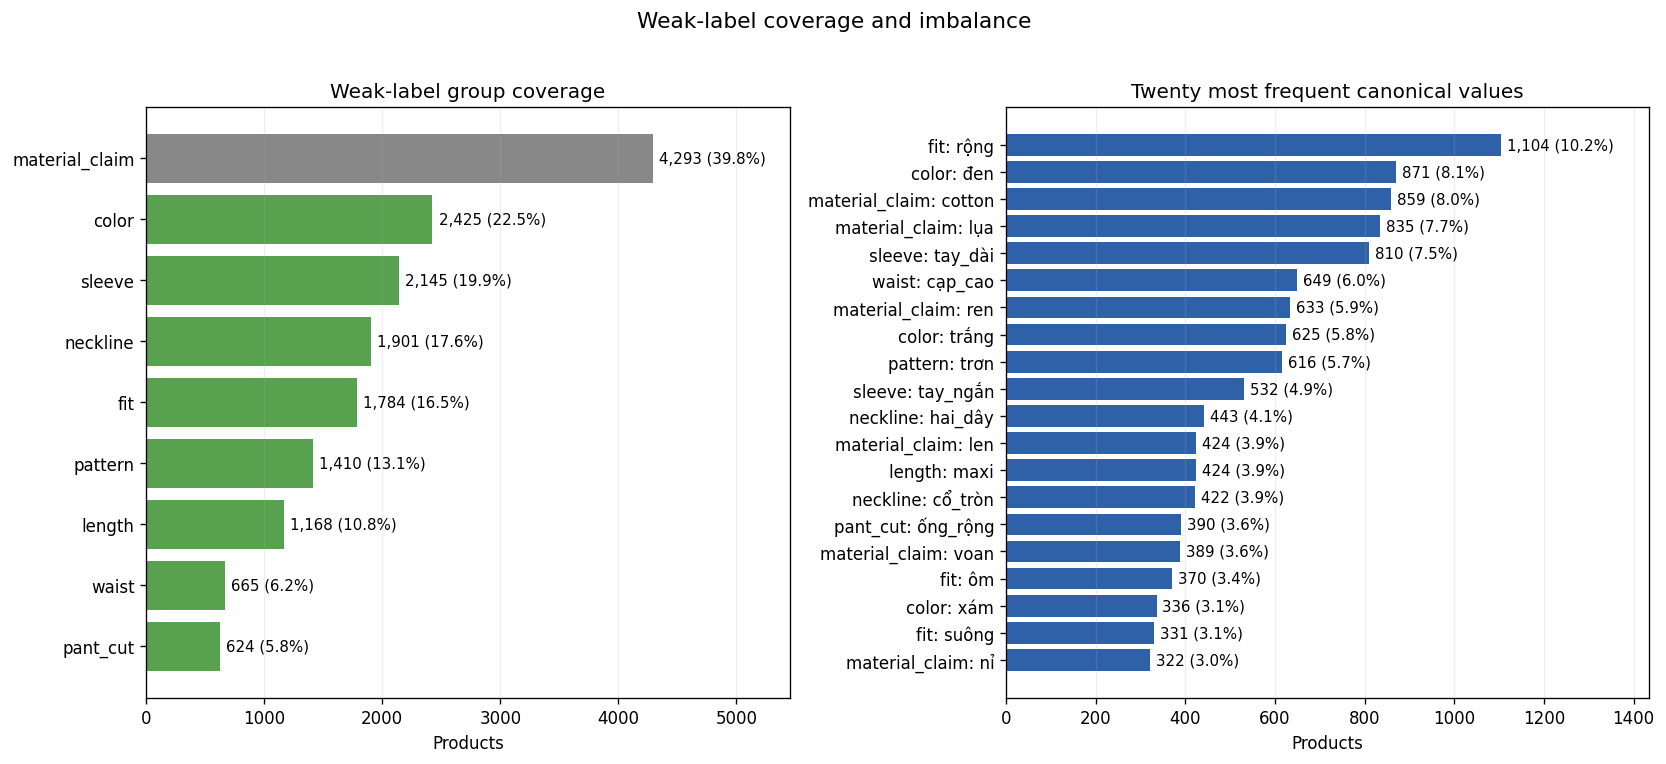

8,707 products (80.64%) contained at least one recognized group.
Interpretation: the long-tailed value distribution motivates minimum-frequency rules, class weighting, and per-attribute reporting.


In [5]:
group_counts = collections.Counter(group for r in records for group in r['title_attributes'])
value_counts = collections.Counter((group, value) for r in records
                                   for group, values in r['title_attributes'].items() for value in values)
groups = [k for k,_ in group_counts.most_common()]
gvalues = [group_counts[k] for k in groups]
top_values = value_counts.most_common(20)
vlabels = [f'{group}: {value}' for (group,value),_ in top_values]
vvalues = [count for _,count in top_values]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
gcolors = [C['gray'] if g=='material_claim' else C['green'] for g in groups[::-1]]
axes[0].barh(groups[::-1], gvalues[::-1], color=gcolors)
annotate_bars(axes[0], gvalues[::-1], denominator=N)
axes[0].set_xlim(0,max(gvalues)*1.27)
axes[0].set_xlabel('Products')
axes[0].set_title('Weak-label group coverage')
axes[0].grid(axis='x',alpha=.2)
axes[1].barh(vlabels[::-1], vvalues[::-1], color=C['blue'])
annotate_bars(axes[1], vvalues[::-1], denominator=N)
axes[1].set_xlim(0,max(vvalues)*1.3)
axes[1].set_xlabel('Products')
axes[1].set_title('Twenty most frequent canonical values')
axes[1].grid(axis='x',alpha=.2)
fig.suptitle('Weak-label coverage and imbalance', y=1.02, fontsize=13)
save_figure(fig, 'figure_3_4_4_weak_label_coverage_values')

print(f'{with_attributes:,} products ({100*with_attributes/N:.2f}%) contained at least one recognized group.')
print('Interpretation: the long-tailed value distribution motivates minimum-frequency rules, class weighting, and per-attribute reporting.')

## 3.4.5 Number of weak attributes per title and group co-occurrence

Canonical values are deduplicated within a title. The co-occurrence matrix reports the percentage of all products in which two weak-label groups appear together; its diagonal is individual group prevalence.

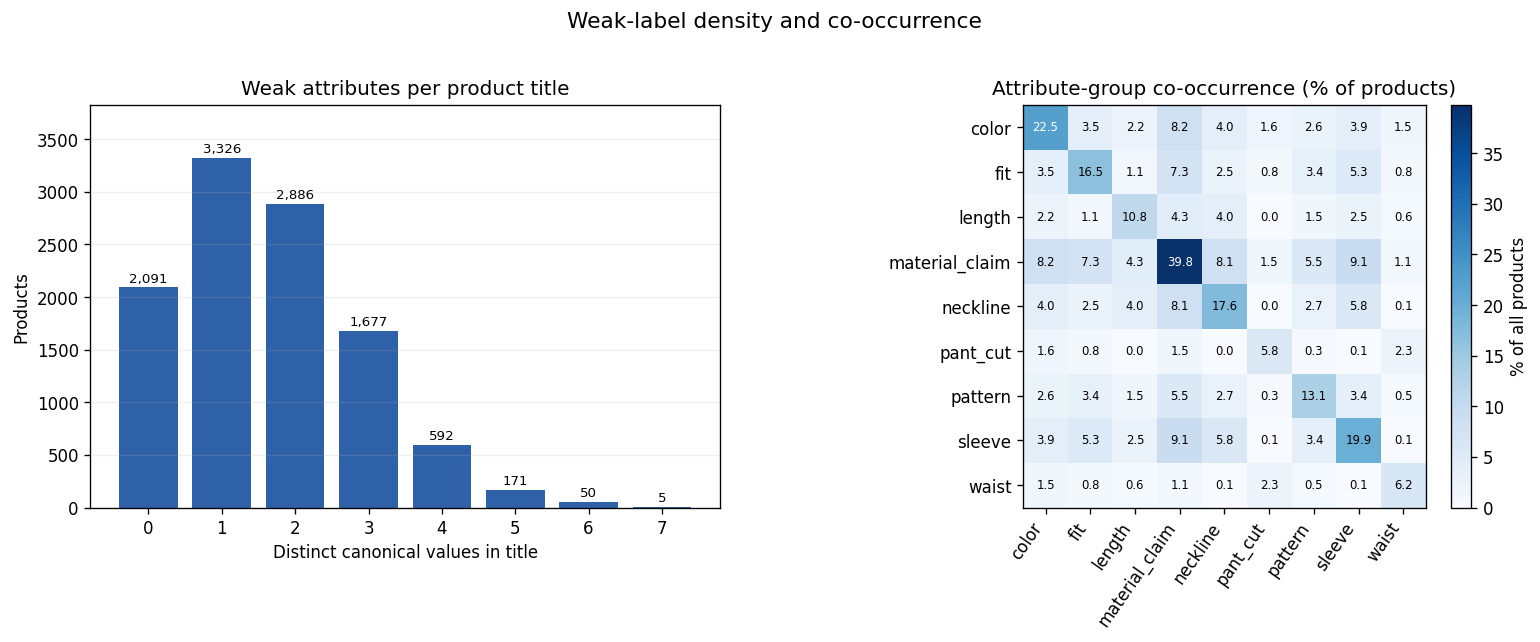

Mean canonical values per product: 1.64; median: 1; maximum: 7.
Co-occurrence indicates which labels appear together in seller titles; it does not prove visual co-occurrence in the product image.


In [6]:
attribute_count = np.array([sum(len(v) for v in r['title_attributes'].values()) for r in records])
hist = collections.Counter(attribute_count)
ordered_counts = list(range(int(attribute_count.max())+1))
hist_values = [hist[k] for k in ordered_counts]
group_names = sorted(group_counts)
co = np.zeros((len(group_names),len(group_names)),dtype=float)
for r in records:
    present = set(r['title_attributes'])
    for i,a in enumerate(group_names):
        for j,b in enumerate(group_names):
            co[i,j] += a in present and b in present
co = 100*co/N
fig, axes = plt.subplots(1,2,figsize=(13,5.2))
axes[0].bar(ordered_counts,hist_values,color=C['blue'])
for x,y in zip(ordered_counts,hist_values):
    axes[0].text(x,y+max(hist_values)*.015,f'{y:,}',ha='center',fontsize=8)
axes[0].set(xlabel='Distinct canonical values in title',ylabel='Products',
            title='Weak attributes per product title')
axes[0].set_xticks(ordered_counts)
axes[0].set_ylim(0,max(hist_values)*1.15)
axes[0].grid(axis='y',alpha=.2)
im=axes[1].imshow(co,cmap='Blues',vmin=0,vmax=max(1,co.max()))
axes[1].set_xticks(range(len(group_names)),group_names,rotation=55,ha='right')
axes[1].set_yticks(range(len(group_names)),group_names)
axes[1].set_title('Attribute-group co-occurrence (% of products)')
for i in range(len(group_names)):
    for j in range(len(group_names)):
        axes[1].text(j,i,f'{co[i,j]:.1f}',ha='center',va='center',fontsize=7,
                     color='white' if co[i,j]>co.max()*.55 else 'black')
fig.colorbar(im,ax=axes[1],fraction=.046,pad=.04,label='% of all products')
fig.suptitle('Weak-label density and co-occurrence',y=1.02,fontsize=13)
save_figure(fig,'figure_3_4_5_weak_label_density_cooccurrence')

print(f'Mean canonical values per product: {attribute_count.mean():.2f}; median: {np.median(attribute_count):.0f}; maximum: {attribute_count.max()}.')
print('Co-occurrence indicates which labels appear together in seller titles; it does not prove visual co-occurrence in the product image.')

## 3.4.6 Noise flags and training exclusions

Flags overlap. Only `listing_multiple_variants` and `possible_negation_review` were exclusion criteria in the completed training pipeline; the remaining flags were retained for audit and later review.

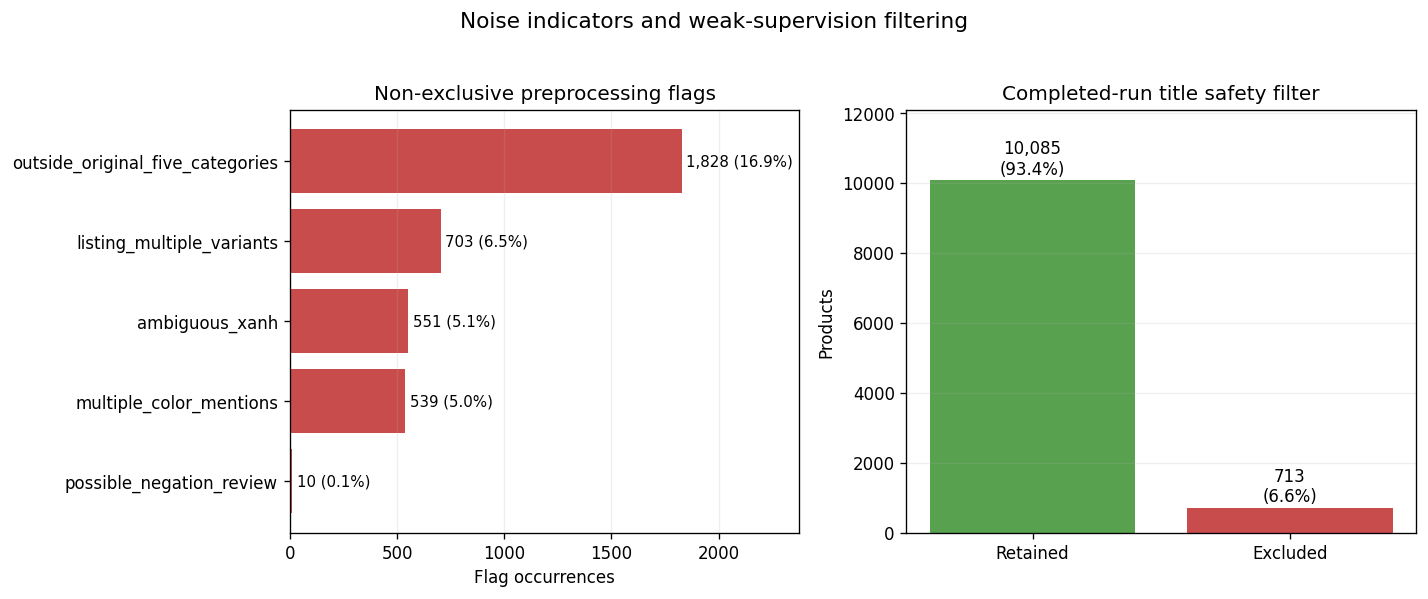

713 records (6.60%) were excluded by the union of the two completed-run filters.
The filters are pattern-based and incomplete; retained does not mean manually verified as correct.


In [7]:
flag_counts = collections.Counter(flag for r in records for flag in r['flags'])
flag_order = [k for k,_ in flag_counts.most_common()]
flag_values = [flag_counts[k] for k in flag_order]
excluded = N-len(safe)
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
axes[0].barh(flag_order[::-1],flag_values[::-1],color=C['red'])
annotate_bars(axes[0],flag_values[::-1],denominator=N)
axes[0].set_xlim(0,max(flag_values)*1.3)
axes[0].set_xlabel('Flag occurrences')
axes[0].set_title('Non-exclusive preprocessing flags')
axes[0].grid(axis='x',alpha=.2)
axes[1].bar(['Retained','Excluded'],[len(safe),excluded],color=[C['green'],C['red']])
for patch,value in zip(axes[1].patches,[len(safe),excluded]):
    axes[1].text(patch.get_x()+patch.get_width()/2,value+N*.015,
                 f'{value:,}\n({100*value/N:.1f}%)',ha='center')
axes[1].set_ylim(0,N*1.12)
axes[1].set_ylabel('Products')
axes[1].set_title('Completed-run title safety filter')
axes[1].grid(axis='y',alpha=.2)
fig.suptitle('Noise indicators and weak-supervision filtering',y=1.03,fontsize=13)
save_figure(fig,'figure_3_4_6_noise_filtering')

print(f'{excluded:,} records ({100*excluded/N:.2f}%) were excluded by the union of the two completed-run filters.')
print('The filters are pattern-based and incomplete; retained does not mean manually verified as correct.')

## 3.4.7 Training vocabulary selection

Document frequency counts each token at most once per training title. The default threshold retains tokens appearing in at least five training titles. The completed model run used this automatic threshold and did not apply an edited `vocabulary_review.csv`.

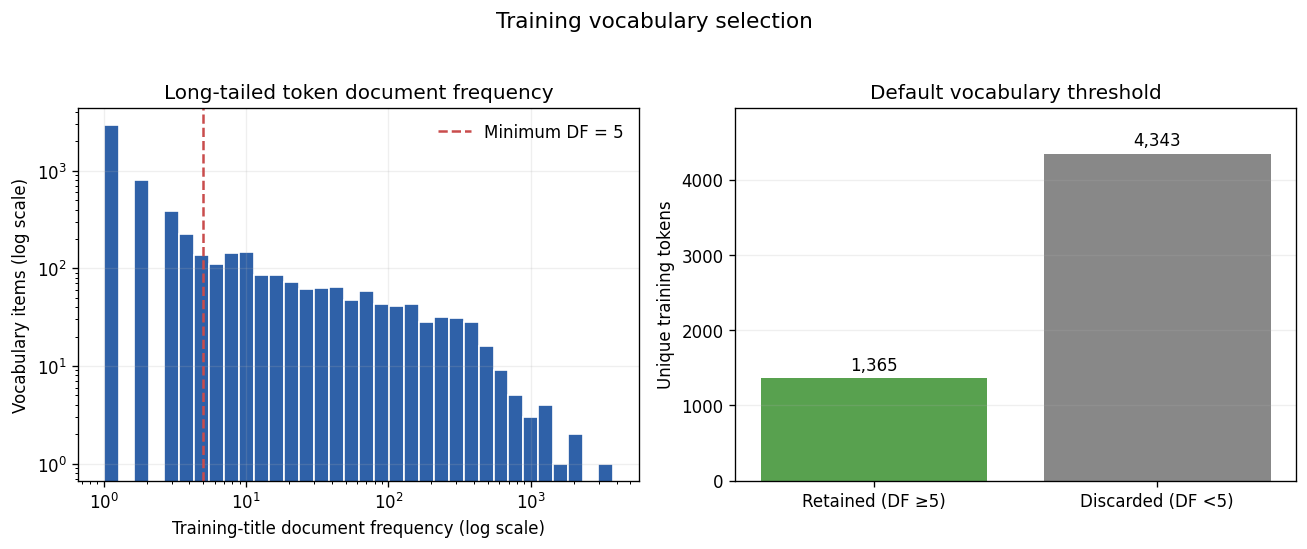

Unique tokens in training titles: 5,708.
Retained by the global audit threshold (DF ≥5): 1,365; discarded: 4,343.
Final model vocabularies are constructed separately by product category, so their sizes differ from this global audit count.


In [8]:
train_records = [r for r in records if r['split']=='train']
document_frequency = collections.Counter(t for r in train_records for t in set(r['tokens']))
dfs = np.array(list(document_frequency.values()))
minimum_df = 5
retained_vocab = sum(dfs>=minimum_df)
discarded_vocab = sum(dfs<minimum_df)
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
log_bins=np.logspace(0,np.log10(dfs.max()+1),35)
axes[0].hist(dfs,bins=log_bins,color=C['blue'],edgecolor='white')
axes[0].axvline(minimum_df,color=C['red'],linestyle='--',label='Minimum DF = 5')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set(xlabel='Training-title document frequency (log scale)',ylabel='Vocabulary items (log scale)',
            title='Long-tailed token document frequency')
axes[0].legend(frameon=False)
axes[0].grid(alpha=.2)
axes[1].bar(['Retained (DF ≥5)','Discarded (DF <5)'],[retained_vocab,discarded_vocab],
            color=[C['green'],C['gray']])
for patch,value in zip(axes[1].patches,[retained_vocab,discarded_vocab]):
    axes[1].text(patch.get_x()+patch.get_width()/2,value+max(retained_vocab,discarded_vocab)*.025,
                 f'{value:,}',ha='center')
axes[1].set_ylim(0,max(retained_vocab,discarded_vocab)*1.14)
axes[1].set_ylabel('Unique training tokens')
axes[1].set_title('Default vocabulary threshold')
axes[1].grid(axis='y',alpha=.2)
fig.suptitle('Training vocabulary selection',y=1.03,fontsize=13)
save_figure(fig,'figure_3_4_7_vocabulary_selection')

print(f'Unique tokens in training titles: {len(document_frequency):,}.')
print(f'Retained by the global audit threshold (DF ≥5): {retained_vocab:,}; discarded: {discarded_vocab:,}.')
print('Final model vocabularies are constructed separately by product category, so their sizes differ from this global audit count.')

## Export numerical tables and report-ready synthesis

The final cell exports the values behind the plots. The central interpretation is that title processing increases terminological consistency and provides scalable supervision, but it does not convert seller text into verified visual labels.

In [9]:
tables = {
    '3_4_1_processing_overview': overview,
    '3_4_4_weak_label_groups': group_counts,
    '3_4_6_noise_flags': flag_counts,
    '3_4_7_vocabulary': {'unique_training_tokens':len(document_frequency),
                         'retained_df_ge_5':retained_vocab,'discarded_df_lt_5':discarded_vocab},
}
for stem,mapping in tables.items():
    with (FIGURE_DIR/f'{stem}.csv').open('w',encoding='utf-8-sig',newline='') as f:
        writer=csv.writer(f)
        writer.writerow(['indicator','count','percentage_of_all_products'])
        for key,value in mapping.items():
            writer.writerow([key,value,100*value/N])
with (FIGURE_DIR/'3_4_3_top_variant_mappings.csv').open('w',encoding='utf-8-sig',newline='') as f:
    writer=csv.writer(f); writer.writerow(['evidence','canonical_value','occurrences'])
    for (source,target),count in variant_mappings.most_common():
        writer.writerow([source,target,count])
with (FIGURE_DIR/'3_4_4_canonical_value_frequency.csv').open('w',encoding='utf-8-sig',newline='') as f:
    writer=csv.writer(f); writer.writerow(['attribute_group','canonical_value','products','percentage'])
    for (group,value),count in value_counts.most_common():
        writer.writerow([group,value,count,100*count/N])

print('REPORT-READY SYNTHESIS')
print(f'The preprocessing pipeline altered the surface form of {changed:,} titles ({100*changed/N:.2f}%). '      f'Rule-based matching identified at least one canonical attribute group in {with_attributes:,} products '      f'({100*with_attributes/N:.2f}%). The final representation contained an average of '      f'{model_tokens.mean():.2f} model tokens per title, compared with {normalized_tokens.mean():.2f} '      f'whitespace-separated tokens before phrase collapsing and filtering. '      f'The completed-run ambiguity filters excluded {excluded:,} records ({100*excluded/N:.2f}%). '      f'The training split contained {len(document_frequency):,} unique tokens, of which {retained_vocab:,} '      f'met the default document-frequency threshold of five in the global audit. '      'These outputs constitute weak seller-derived supervision and were not treated as manually verified visual ground truth.')
print('\nGenerated files:')
for path in sorted(FIGURE_DIR.iterdir()):
    print(' -',path.relative_to(PROJECT_ROOT))

REPORT-READY SYNTHESIS
The preprocessing pipeline altered the surface form of 10,747 titles (99.53%). Rule-based matching identified at least one canonical attribute group in 8,707 products (80.64%). The final representation contained an average of 13.37 model tokens per title, compared with 18.88 whitespace-separated tokens before phrase collapsing and filtering. The completed-run ambiguity filters excluded 713 records (6.60%). The training split contained 5,708 unique tokens, of which 1,365 met the default document-frequency threshold of five in the global audit. These outputs constitute weak seller-derived supervision and were not treated as manually verified visual ground truth.

Generated files:
 - outputs\figures\title_processing\3_4_1_processing_overview.csv
 - outputs\figures\title_processing\3_4_3_top_variant_mappings.csv
 - outputs\figures\title_processing\3_4_4_canonical_value_frequency.csv
 - outputs\figures\title_processing\3_4_4_weak_label_groups.csv
 - outputs\figures\ti